In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# The notebook runs from the notebooks/ folder, so go up one level to the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = sqlite3.connect(ROOT / "data" / "processed" / "skating.db")


def query(sql):
    """Run a SQL query and return the result as a pandas DataFrame."""
    return pd.read_sql(sql, con)


# Chart style: light grid behind the data, no top/right frame
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "figure.dpi": 110,
})
COLORS = {"M": "#2a78d6", "W": "#eb6834"}   # blue for men, orange for women

In [2]:
perf = query("""
    SELECT s.category, s.segment, p.tes, p.pcs, p.total
    FROM performances p
    JOIN segments s ON p.segment_id = s.id
""")
perf.head()

,category,segment,tes,pcs,total
0,M,FS,101.64,88.71,190.35
1,M,FS,101.52,82.06,183.58
2,M,FS,98.65,83.25,181.90
3,M,FS,91.38,83.85,175.23
4,M,FS,88.51,80.86,169.37


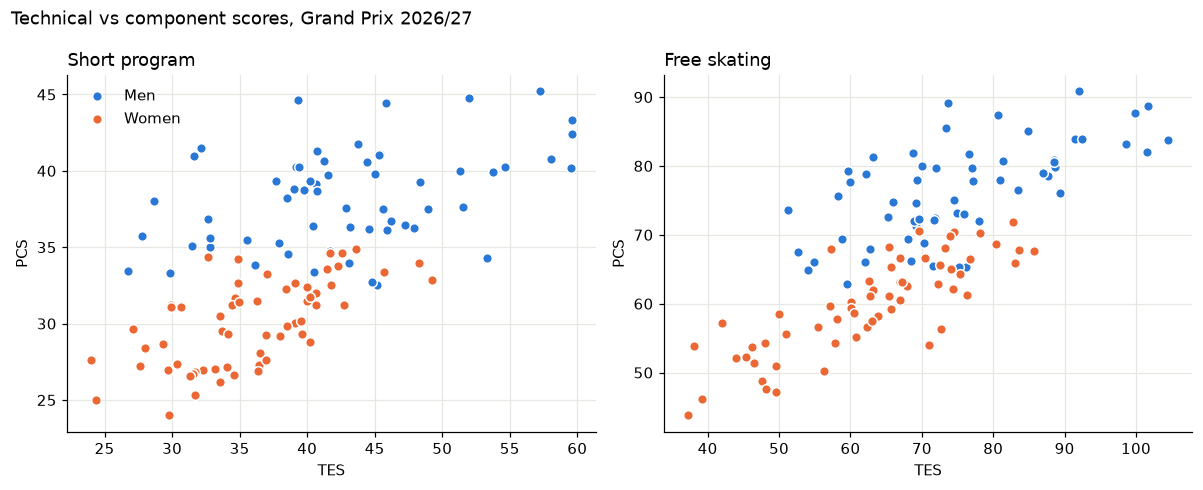

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, segment, title in zip(axes, ["SP", "FS"], ["Short program", "Free skating"]):
    for category, label in [("M", "Men"), ("W", "Women")]:
        d = perf[(perf.segment == segment) & (perf.category == category)]
        ax.scatter(d.tes, d.pcs, s=40, color=COLORS[category], label=label,
                   edgecolor="white", linewidth=1)
    ax.set_title(title, loc="left")
    ax.set_xlabel("TES")
    ax.set_ylabel("PCS")

axes[0].legend(frameon=False)
fig.suptitle("Technical vs component scores, Grand Prix 2026/27", x=0.01, ha="left")
fig.tight_layout()
plt.show()

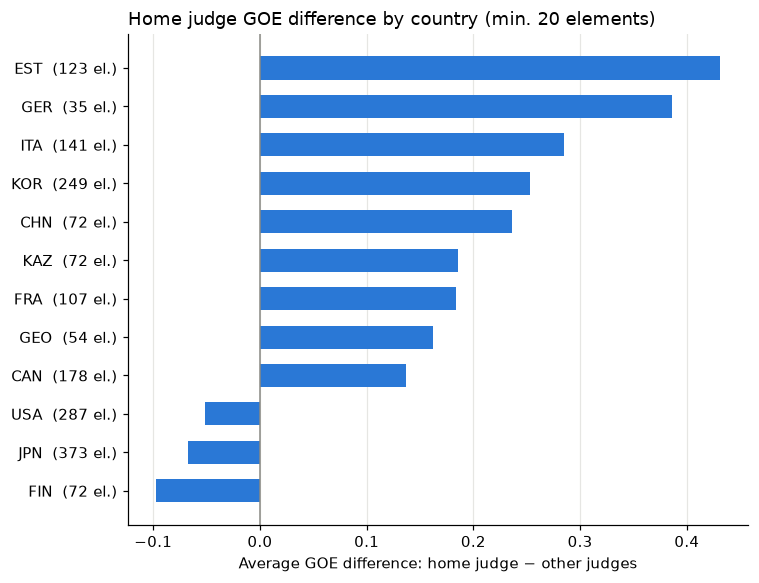

In [4]:
home = query("""
    WITH judged AS (
        SELECT ejs.goe, p.nation AS skater_nation, pa.nation AS judge_nation,
               SUM(ejs.goe)   OVER (PARTITION BY ejs.element_id) AS panel_sum,
               COUNT(ejs.goe) OVER (PARTITION BY ejs.element_id) AS panel_count
        FROM element_judge_scores ejs
        JOIN elements e     ON e.id = ejs.element_id
        JOIN performances p ON p.id = e.performance_id
        JOIN panel pa       ON pa.segment_id = p.segment_id AND pa.judge_number = ejs.judge
        WHERE ejs.goe IS NOT NULL
    )
    SELECT skater_nation AS nation, COUNT(*) AS elements,
           AVG(goe - 1.0 * (panel_sum - goe) / (panel_count - 1)) AS avg_delta
    FROM judged
    WHERE judge_nation = skater_nation
    GROUP BY skater_nation
    HAVING COUNT(*) >= 20
""").sort_values("avg_delta")

labels = [f"{n}  ({e} el.)" for n, e in zip(home.nation, home.elements)]

fig, ax = plt.subplots(figsize=(7, 0.35 * len(home) + 1.2))
ax.barh(labels, home.avg_delta, color=COLORS["M"], height=0.6)
ax.axvline(0, color="#8a8a85", linewidth=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Average GOE difference: home judge − other judges")
ax.set_title("Home judge GOE difference by country (min. 20 elements)", loc="left")
fig.tight_layout()
plt.show()